**Validated reading copy.** Run the [source notebook](../../../../Tools/PracticalWorkflow_examples/Mixed_Data_Workflow.ipynb) in its original directory. This snapshot includes checked outputs; source SHA-256: `60d631494abcd6833f90ba9d2b27c50c02d047bf69c8d492ed1368fefd7158d8`. Timings describe this recorded environment, not a performance guarantee.

# A practical XAI workflow for mixed, incomplete data

**Question:** how can we explain a prediction using the original columns a practitioner recognizes, when the trained model receives imputed, scaled and one-hot-encoded values?

This offline example predicts whether a **synthetic order** is returned. It combines numerical and categorical columns, missing values and a deliberately unseen test category. A single fitted scikit-learn pipeline owns preprocessing and prediction. We measure held-out performance, explain one fixed raw row using exact model-agnostic Shapley values, and calculate raw-column permutation importance.

Install `requirements-tabular.txt` and run from this folder. No external data, weights, Java or neural framework is needed. Six raw features keep exact enumeration small. The helper `workflow_helpers.py` makes schema checks and the finite-background Shapley game explicit; the final cell saves results and metadata under the ignored `validation/mixed-data-workflow/` directory.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import subprocess
import sys
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from workflow_helpers import exact_raw_shapley, transformed_groups, unknown_categories, validate_raw_frame

ROOT = Path.cwd().resolve().parents[1]
assert (ROOT / 'README.md').exists(), 'Run from Tools/PracticalWorkflow_examples/.'
OUTPUT = ROOT / 'validation' / 'mixed-data-workflow'
OUTPUT.mkdir(parents=True, exist_ok=True)
NUMERICAL = ['order_value', 'delivery_days', 'prior_orders']
CATEGORICAL = ['region', 'channel', 'gift_wrap']
FEATURES = NUMERICAL + CATEGORICAL
TARGET = 'returned'
SEED = 42
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

/Users/navid/Documents/Codex/2026-10-28/makew/work/Introduction-to-XAI/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Generate data, then reserve an unseen-category test slice

The complete-data generating probability depends on order value, delivery delay, previous orders and three categorical variables. Labels are sampled from that probability. We then introduce explicit missing values, without using the labels to decide which values are missing.

Forty orders come from an `island` region that is **entirely reserved for testing**; it has a higher return probability in this constructed world. The remaining orders receive a stratified 75/25 train/test split. This deliberately tests a deployment change; the combined test distribution is not an ordinary IID holdout. We report the seen-category and unseen-category slices separately. It does not characterize all possible new categories.

In [2]:
rng = np.random.default_rng(SEED)
n = 1000
raw_complete = pd.DataFrame({
    'order_value': rng.gamma(shape=2., scale=45., size=n),
    'delivery_days': rng.poisson(4., n).astype(float) + 1,
    'prior_orders': rng.poisson(3., n).astype(float),
    'region': rng.choice(['north', 'south', 'central'], n),
    'channel': rng.choice(['web', 'mobile', 'store'], n, p=[.45, .4, .15]),
    'gift_wrap': rng.choice(['yes', 'no'], n, p=[.2, .8]),
}, index=pd.Index(np.arange(n), name='order_id'))
island_indices = np.sort(rng.choice(n, 40, replace=False))
raw_complete.loc[island_indices, 'region'] = 'island'
region_effect = raw_complete.region.map({'north':0., 'south':.25, 'central':-.1, 'island':1.4}).to_numpy()
channel_effect = raw_complete.channel.map({'web':0., 'mobile':.35, 'store':-.2}).to_numpy()
logit = (-2. + .012 * (raw_complete.order_value.to_numpy() - 70.)
         + .35 * (raw_complete.delivery_days.to_numpy() - 4.)
         - .12 * raw_complete.prior_orders.to_numpy() + region_effect + channel_effect
         - .4 * (raw_complete.gift_wrap.to_numpy() == 'yes'))
generating_probability = 1 / (1 + np.exp(-logit))
y = pd.Series(np.where(rng.binomial(1, generating_probability), TARGET, 'kept'), index=raw_complete.index, name='outcome')
raw = raw_complete.copy()
missing_rates = {'order_value':.12, 'delivery_days':.10, 'prior_orders':.05,
                 'region':.05, 'channel':.08, 'gift_wrap':.03}
for column, rate in missing_rates.items():
    mask = rng.random(n) < rate
    if column == 'region':
        mask[island_indices] = False  # Preserve the explicitly defined unseen-category slice.
    raw.loc[mask, column] = np.nan
# This first unseen-category illustration also has one missing numerical value.
raw.loc[island_indices[0], 'delivery_days'] = np.nan
raw = validate_raw_frame(raw, NUMERICAL, CATEGORICAL)
known_indices = raw.index.difference(island_indices)
train_indices, known_test_indices = train_test_split(
    known_indices.to_numpy(), test_size=.25, random_state=SEED, stratify=y.loc[known_indices],
)
test_indices = np.concatenate([known_test_indices, island_indices])
X_train, X_test = raw.loc[train_indices].copy(), raw.loc[test_indices].copy()
y_train, y_test = y.loc[train_indices], y.loc[test_indices]
assert set(train_indices).isdisjoint(test_indices)
assert 'island' not in set(X_train.region.dropna())
display(pd.DataFrame({'training_missing_fraction': X_train.isna().mean(),
                      'test_missing_fraction': X_test.isna().mean()}))
print(f'Train rows: {len(X_train)}; seen-category test rows: {len(known_test_indices)}; unseen-category test rows: {len(island_indices)}')

,training_missing_fraction,test_missing_fraction
order_value,0.136111,0.100000
delivery_days,0.118056,0.092857
prior_orders,0.063889,0.046429
region,0.044444,0.035714
channel,0.088889,0.092857
gift_wrap,0.031944,0.014286


Train rows: 720; seen-category test rows: 240; unseen-category test rows: 40


## 2. Keep learned preprocessing inside the model pipeline

Numerical columns use training medians, missingness indicators and standardization. Categorical columns use an explicit missing token and one-hot encoding. `handle_unknown='ignore'` accepts new category strings by producing an all-zero block for that raw feature. This prevents an exception; it does **not** give the model knowledge of that category.

Fit the pipeline on training rows only. An imputation statistic, scaling parameter, category vocabulary, explanation background or tuning decision learned from the test set would change the interpretation of the holdout. This example does no hyperparameter tuning; tune inside training-only cross-validation in an application.

In [3]:
numerical_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='median', add_indicator=True)),
    ('scale', StandardScaler()),
])
categorical_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='constant', fill_value='__missing__')),
    ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ('numerical', numerical_pipeline, NUMERICAL),
    ('categorical', categorical_pipeline, CATEGORICAL),
], remainder='drop', verbose_feature_names_out=True)
pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('model', LogisticRegression(C=1., max_iter=1000, random_state=SEED)),
])
pipeline.fit(X_train, y_train)
fitted_preprocessor = pipeline.named_steps['preprocess']
class_names = list(pipeline.classes_)
target_index = class_names.index(TARGET)
print('Model class order:', class_names, '; explicitly explained label:', TARGET, '; column:', target_index)
training_medians = fitted_preprocessor.named_transformers_['numerical'].named_steps['impute'].statistics_.copy()
np.testing.assert_allclose(training_medians, X_train[NUMERICAL].median().to_numpy())
assert unknown_categories(X_train, fitted_preprocessor, CATEGORICAL) == {}
display(pd.DataFrame([{'raw_feature': key, 'unseen_values': values}
                      for key, values in unknown_categories(X_test, fitted_preprocessor, CATEGORICAL).items()]))

Model class order: ['kept', 'returned'] ; explicitly explained label: returned ; column: 1


,raw_feature,unseen_values
0,region,[island]


## 3. Evaluate the predictor before explaining it

ROC AUC measures ranking, accuracy uses the default class decision, and Brier score measures squared probability error. None is a measure of explanation quality. The subset results have only 40 unseen-category rows, so differences are descriptive and uncertain. This model has not been calibrated separately; its numbers are model probabilities, not verified confidence guarantees.

,slice,n,observed_return_fraction,mean_model_probability,roc_auc,accuracy,brier_score
0,All test rows,280,0.246,0.203,0.652,0.761,0.175
1,Seen-category test rows,240,0.204,0.193,0.629,0.792,0.157
2,Unseen island category,40,0.500,0.257,0.702,0.575,0.281


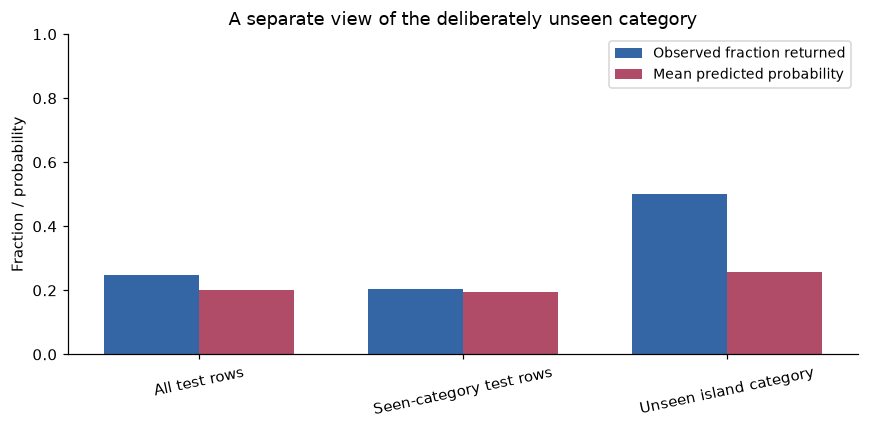

In [4]:
probability = pipeline.predict_proba(X_test)[:, target_index]
binary_y = (y_test == TARGET).to_numpy()
is_unseen = X_test.region.eq('island').to_numpy()
quality_rows = []
for name, mask in [('All test rows', np.ones(len(X_test), dtype=bool)),
                   ('Seen-category test rows', ~is_unseen), ('Unseen island category', is_unseen)]:
    truth = binary_y[mask]
    quality_rows.append(dict(slice=name, n=int(mask.sum()), observed_return_fraction=float(truth.mean()),
                             mean_model_probability=float(probability[mask].mean()),
                             roc_auc=roc_auc_score(truth, probability[mask]) if len(np.unique(truth)) == 2 else np.nan,
                             accuracy=accuracy_score(truth, probability[mask] >= .5),
                             brier_score=brier_score_loss(truth, probability[mask])))
quality = pd.DataFrame(quality_rows)
display(quality.round(3))
fig, ax = plt.subplots(figsize=(8, 4))
positions = np.arange(len(quality))
ax.bar(positions - .18, quality.observed_return_fraction, width=.36, label='Observed fraction returned', color='#3465a4')
ax.bar(positions + .18, quality.mean_model_probability, width=.36, label='Mean predicted probability', color='#b04b68')
ax.set(xticks=positions, xticklabels=quality['slice'], ylim=(0, 1), ylabel='Fraction / probability',
       title='A separate view of the deliberately unseen category')
ax.tick_params(axis='x', rotation=12)
ax.legend(fontsize=9)
plt.tight_layout()
fig.savefig(OUTPUT / 'heldout_slices.png', bbox_inches='tight')
plt.show()

## 4. Recover the original feature groups

The model's numerical input has more columns than the six raw features. Each category expands into several indicator columns; a numerical feature with training missingness expands into its value and missing indicator. Every transformed column must belong to exactly one original feature in this pipeline.

We will replace a **raw feature before preprocessing**. This moves its one-hot block or value-plus-missingness indicator together, so impossible independent dummy combinations are not introduced. The group mapping is also useful for labeling transformed-model outputs. Summing arbitrary dummy-level Shapley values is not generally the same game as treating the entire original feature as one player.

In [5]:
groups = transformed_groups(fitted_preprocessor, NUMERICAL, CATEGORICAL)
encoded_names = fitted_preprocessor.get_feature_names_out()
flattened = [index for block in groups.values() for index in block]
assert sorted(flattened) == list(range(len(encoded_names))) and len(flattened) == len(set(flattened))
group_table = pd.DataFrame([{'raw_feature': name, 'encoded_columns': ', '.join(encoded_names[indices])}
                            for name, indices in groups.items()])
display(group_table)

# Fixed query chosen by row identity and unseen-category membership, not outcome or attribution.
query_id = int(island_indices[0])
query = validate_raw_frame(X_test.loc[[query_id]], NUMERICAL, CATEGORICAL)
background_rng = np.random.default_rng(137)
background_ids = background_rng.choice(X_train.index.to_numpy(), 48, replace=False)
background = X_train.loc[background_ids].copy()
display(query)
query_encoded = fitted_preprocessor.transform(query)
donor_encoded = fitted_preprocessor.transform(background.iloc[[0]])
for feature, indices in groups.items():
    hybrid_raw = query.copy()
    hybrid_raw[feature] = background.iloc[0][feature]
    hybrid_encoded = query_encoded.copy()
    hybrid_encoded[:, indices] = donor_encoded[:, indices]
    np.testing.assert_allclose(fitted_preprocessor.transform(hybrid_raw), hybrid_encoded)
    np.testing.assert_allclose(pipeline.predict_proba(hybrid_raw), pipeline.named_steps['model'].predict_proba(hybrid_encoded))
print('Raw replacement equals complete encoded-group replacement for all six features, including missingness indicators.')

,raw_feature,encoded_columns
0,order_value,"numerical__order_value, numerical__missingindi..."
1,delivery_days,"numerical__delivery_days, numerical__missingin..."
2,prior_orders,"numerical__prior_orders, numerical__missingind..."
3,region,"categorical__region___missing__, categorical__..."
4,channel,"categorical__channel___missing__, categorical_..."
5,gift_wrap,"categorical__gift_wrap___missing__, categorica..."


,order_value,delivery_days,prior_orders,region,channel,gift_wrap
order_id,,,,,,
22,137.870578,NaN,7.0,island,mobile,no


Raw replacement equals complete encoded-group replacement for all six features, including missingness indicators.


## 5. Exact model-agnostic Shapley values in raw feature space

For coalition $S$, define $v(S)=\frac{1}{|B|}\sum_{b\in B}f_{\text{returned}}(x_S,b_{\bar S})$, using **48 training rows** as the background. We enumerate all $2^6=64$ coalitions and apply the standard Shapley weights. The helper returns exact values for this finite-background game; SHAP's plotting API displays them. They add to a change in **returned-class probability**, not log odds.

This marginal replacement respects the encoding of each raw feature, but can still break relationships **between** raw features. It is not conditional SHAP, a causal effect, or an estimate of an actual change an order manager should make. The training background deliberately contains no `island` examples. An additive accounting of an unsupported category cannot certify generalization to that category.

Exact enumeration costs $2^d|B|$ model evaluations; it is suitable for this small example. For many features use a sampled model-agnostic estimator with the same raw-feature masking semantics and report its approximation uncertainty. Our helper rejects more than 12 features to prevent accidental exponential work.

Order 22; observed outcome: kept; P(returned): 0.238
Background mean: 0.193; enumerated rows: 3072; time: 0.010s


,raw_feature,raw_value,probability_contribution
0,order_value,137.870578,0.084190
1,delivery_days,NaN,-0.050954
2,prior_orders,7.0,-0.040858
3,region,island,0.019153
4,channel,mobile,0.025903
5,gift_wrap,no,0.006856


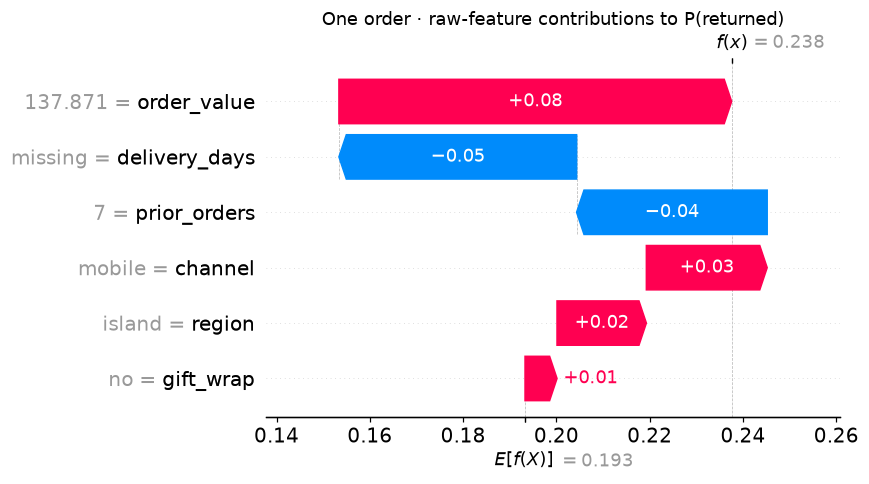

In [6]:
started = perf_counter()
explanation = exact_raw_shapley(pipeline, query, background, TARGET)
explanation_seconds = perf_counter() - started
assert explanation['target_index'] == target_index
np.testing.assert_allclose(explanation['base_value'], pipeline.predict_proba(background)[:, target_index].mean(), atol=1e-12)
np.testing.assert_allclose(explanation['prediction'], pipeline.predict_proba(query)[0, target_index], atol=1e-12)
np.testing.assert_allclose(explanation['base_value'] + explanation['values'].sum(), explanation['prediction'], atol=1e-12)
# Column order is a schema concern: normalize named columns before invoking the model.
reordered = validate_raw_frame(query.loc[:, list(reversed(FEATURES))], NUMERICAL, CATEGORICAL)
np.testing.assert_allclose(pipeline.predict_proba(reordered), pipeline.predict_proba(query))
print(f'Order {query_id}; observed outcome: {y_test.loc[query_id]}; P(returned): {explanation["prediction"]:.3f}')
print(f'Background mean: {explanation["base_value"]:.3f}; enumerated rows: {explanation["evaluated_rows"]}; time: {explanation_seconds:.3f}s')
attribution_table = pd.DataFrame({'raw_feature': FEATURES, 'raw_value': query.iloc[0].to_list(),
                                  'probability_contribution': explanation['values']})
display(attribution_table)
display_values = np.array(['missing' if pd.isna(value) else value for value in query.iloc[0]], dtype=object)
shap_explanation = shap.Explanation(values=explanation['values'], base_values=explanation['base_value'],
                                     data=display_values, feature_names=FEATURES)
shap.plots.waterfall(shap_explanation, max_display=len(FEATURES), show=False)
plt.title('One order · raw-feature contributions to P(returned)')
plt.tight_layout()
plt.gcf().savefig(OUTPUT / 'raw_feature_shapley.png', bbox_inches='tight')
plt.show()

## 6. Global importance on raw columns

Permutation importance evaluates the full fitted pipeline after shuffling one original column, including its missing values. Preprocessing runs again using the **same fitted statistics**. The score is loss in held-out ROC AUC; it is unrelated to the units of the local probability contributions above.

We show the ordinary seen-category holdout, keeping the deliberately shifted category as a separate diagnostic. Shuffling can break cross-feature relationships, and ten repetitions measure shuffle variation, not a confidence interval for population importance. Negative values are possible. We do not refit the pipeline during this calculation.

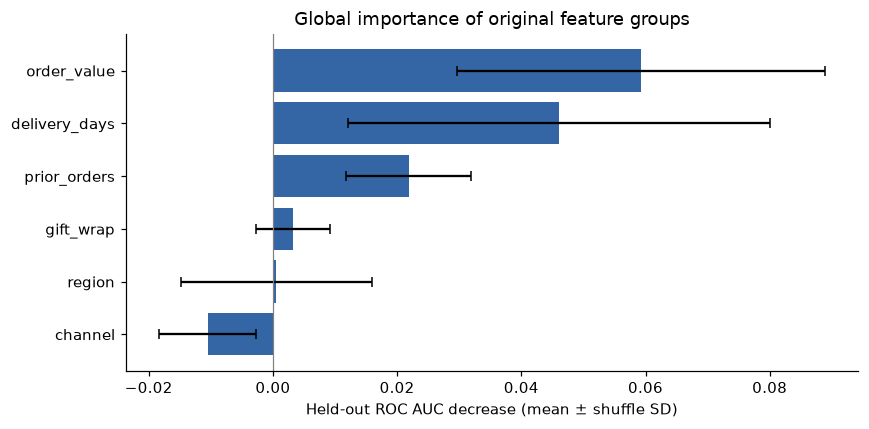

In [7]:
def returned_auc(estimator, rows, labels):
    column = list(estimator.classes_).index(TARGET)
    return roc_auc_score(np.asarray(labels) == TARGET, estimator.predict_proba(rows)[:, column])

permutation = permutation_importance(pipeline, X_test.loc[known_test_indices], y_test.loc[known_test_indices],
                                     scoring=returned_auc, n_repeats=10, random_state=SEED, n_jobs=1)
importance = pd.DataFrame({'raw_feature': FEATURES, 'auc_decrease': permutation.importances_mean,
                           'shuffle_sd': permutation.importances_std}).sort_values('auc_decrease')
np.testing.assert_allclose(training_medians, fitted_preprocessor.named_transformers_['numerical'].named_steps['impute'].statistics_)
assert unknown_categories(X_train, fitted_preprocessor, CATEGORICAL) == {}
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(importance.raw_feature, importance.auc_decrease, xerr=importance.shuffle_sd, capsize=3, color='#3465a4')
ax.axvline(0, color='gray', lw=.8)
ax.set(xlabel='Held-out ROC AUC decrease (mean ± shuffle SD)', title='Global importance of original feature groups')
plt.tight_layout()
fig.savefig(OUTPUT / 'raw_feature_permutation.png', bbox_inches='tight')
plt.show()

## 7. New-row schema checks and a false-confidence trap

The schema validator checks expected names, numeric values, missing values and string categories, and restores the trained column order. It rejects extra/missing columns instead of silently discarding a potential mistake. It does not enforce application-specific units, ranges, cross-column constraints, or data quality; add those checks for your own data.

An unseen category passes the structural schema and is separately reported for review. Two different unknown region names both become the same all-zero region block, so they produce **identical predictions** if the other columns match. This is an encoding limitation, not evidence that the regions have identical outcomes. In production, choose and document an unknown-category policy (for example, route such rows for review rather than relying on the model alone).

In [8]:
new_orders = pd.DataFrame([
    {'order_value':85., 'delivery_days':np.nan, 'prior_orders':2., 'region':'island', 'channel':'mobile', 'gift_wrap':'no'},
    {'order_value':85., 'delivery_days':np.nan, 'prior_orders':2., 'region':'a_different_new_region', 'channel':'mobile', 'gift_wrap':'no'},
])
new_orders = validate_raw_frame(new_orders, NUMERICAL, CATEGORICAL)
unseen_report = unknown_categories(new_orders, fitted_preprocessor, CATEGORICAL)
display(pd.DataFrame([{'feature': key, 'unseen_values': values} for key, values in unseen_report.items()]))
new_encoded = fitted_preprocessor.transform(new_orders)
np.testing.assert_allclose(new_encoded[:, groups['region']], 0)
np.testing.assert_allclose(new_encoded[0], new_encoded[1])
new_probabilities = pipeline.predict_proba(new_orders)[:, target_index]
np.testing.assert_allclose(new_probabilities[0], new_probabilities[1])
display(new_orders.assign(predicted_return_probability=new_probabilities))

# Deliberate bad input: a renamed measurement must fail before model invocation.
try:
    validate_raw_frame(new_orders.rename(columns={'order_value':'value_in_cents'}), NUMERICAL, CATEGORICAL)
except ValueError as error:
    print('Expected schema rejection:', error)
else:
    raise AssertionError('The deliberately incorrect schema was accepted.')

,feature,unseen_values
0,region,"[a_different_new_region, island]"


,order_value,delivery_days,prior_orders,region,channel,gift_wrap,predicted_return_probability
0,85.0,NaN,2.0,island,mobile,no,0.200764
1,85.0,NaN,2.0,a_different_new_region,mobile,no,0.200764


Expected schema rejection: Schema mismatch: missing=['order_value']; unexpected=['value_in_cents']


## 8. Adapt this workflow to your own dataframe and model

1. Replace the synthetic generator with your dataframe; specify numerical/categorical names, target label and units. Keep identifiers and outcome-derived fields out of predictors. Decide what a missing value means.
2. Choose an appropriate split for the deployment question: time, patient/customer groups or another unit may matter more than a random row split. Reserve the test set before fitting imputers, category vocabularies or models.
3. Replace the final estimator while keeping preprocessing in one fitted pipeline. Preserve a documented `predict_proba(raw_rows)` interface and locate the requested output through `classes_` rather than guessing its column.
4. Check prediction performance and calibration on held-out data and relevant slices. Select explanation cases using a disclosed protocol; include failures. This notebook's single unseen-category row illustrates the mechanics, not a representative study.
5. Select a training-derived background that matches the explanation question. Mask original feature groups and validate additivity/output units. Report dependence and replacement assumptions.
6. Validate each incoming dataframe against the schema, report unknown categories, and implement the application-specific response to unsupported inputs. Store model, schema and explanation settings together when deploying.

This workflow is educational. Grouping and schema checks avoid specific errors; they do not establish fairness, causality, robustness or fitness for a particular deployment.

In [9]:
attribution_table.to_csv(OUTPUT / 'local_attributions.csv', index=False)
importance.to_csv(OUTPUT / 'permutation_importance.csv', index=False)
quality.to_csv(OUTPUT / 'heldout_metrics.csv', index=False)
pd.DataFrame(permutation.importances.T, columns=FEATURES).to_csv(OUTPUT / 'permutation_repeats.csv', index=False)
try:
    commit = subprocess.check_output(['git', 'rev-parse', 'HEAD'], cwd=ROOT, text=True).strip()
    git_dirty = bool(subprocess.check_output(['git', 'status', '--porcelain'], cwd=ROOT, text=True).strip())
except (OSError, subprocess.CalledProcessError):
    commit = None
    git_dirty = None
raw_bytes = raw.to_csv(index=True).encode()
report = dict(
    schema_version=1, study='Mixed-data raw-feature workflow', git_commit=commit, git_dirty=git_dirty,
    source_sha256={filename:hashlib.sha256(Path(filename).read_bytes()).hexdigest()
                   for filename in ['Mixed_Data_Workflow.ipynb', 'workflow_helpers.py']},
    dataset_sha256=hashlib.sha256(raw_bytes).hexdigest(),
    labels_sha256=hashlib.sha256(y.to_csv(index=True).encode()).hexdigest(),
    seeds={'generator_and_split':SEED, 'background':137, 'permutation':SEED},
    train_indices=train_indices.tolist(), test_indices=test_indices.tolist(),
    known_test_indices=known_test_indices.tolist(), unseen_category_indices=island_indices.tolist(),
    background_indices=background_ids.tolist(), query_id=query_id,
    schema={'numerical':NUMERICAL, 'categorical':CATEGORICAL, 'target_label':TARGET, 'class_order':class_names},
    preprocessing={'numeric_imputation':'training median with missingness indicators', 'numeric_scaling':'StandardScaler',
                   'categorical_imputation':'__missing__', 'encoding':'OneHotEncoder(handle_unknown=ignore, no dropped categories)'},
    encoded_feature_groups={name:list(map(int, indices)) for name, indices in groups.items()},
    model={'type':'LogisticRegression', 'C':1., 'max_iter':1000},
    explanation={'definition':'Exact Shapley for marginal replacement of raw feature groups using 48 training-background rows',
                 'units':'returned-class probability', 'base_value':float(explanation['base_value']),
                 'prediction':float(explanation['prediction']), 'values':explanation['values'].tolist(),
                 'coalition_values':explanation['coalition_values'].tolist(),
                 'evaluated_rows':explanation['evaluated_rows'], 'seconds':explanation_seconds},
    environment={'python':sys.version, 'platform':platform.platform(),
                 'packages':{name:importlib.metadata.version(name) for name in ['numpy','pandas','scikit-learn','shap','matplotlib']}},
    tables={'heldout_metrics':json.loads(quality.to_json(orient='records')),
            'permutation_importance':json.loads(importance.to_json(orient='records'))},
    caveats=['Unseen category is an intentional distribution shift, not an IID slice.',
             'Shapley additivity does not validate calibration or causality.',
             'Raw-feature masking preserves encoding groups but can break cross-feature dependence.'],
)
(OUTPUT / 'results.json').write_text(json.dumps(report, indent=2, allow_nan=False) + '\n')
print(f'Saved manifest, metrics, attributions and plots to {OUTPUT}')

Saved manifest, metrics, attributions and plots to /Users/navid/Documents/Codex/2026-10-28/makew/work/Introduction-to-XAI/validation/mixed-data-workflow


## References

- [scikit-learn: preprocessing and leakage pitfalls](https://scikit-learn.org/stable/common_pitfalls.html), [ColumnTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html), and [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html).
- [Lundberg & Lee: A Unified Approach to Interpreting Model Predictions](https://arxiv.org/abs/1705.07874), for Shapley additive explanations. This notebook states the finite-background game explicitly and enumerates it directly.
- [SHAP: explaining standardized features](https://shap.readthedocs.io/en/latest/example_notebooks/tabular_examples/linear_models/Explaining%20a%20model%20that%20uses%20standardized%20features.html), including the distinction between one-to-one feature transformations and transformations that mix features.
- Continue with [Evaluation and Sensitivity](../../../../Tools/Evaluation_examples/Evaluation_and_Sensitivity.ipynb) for controlled perturbation tests, uncertainty sources and randomized controls.